# $\rho^0 \rightarrow \pi^+\pi^-$ invariant mass

Use the reconstructed pion momenta in `hepgen_skim.root`. Pions are selected by their generated PID and are required to have a reconstructed track.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import uproot

ROOT_PATH = Path("/Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/hepgen_uni_z_ALL.root")
TREE_NAME = "particles"
PION_MASS_GEV = 0.13957039


In [8]:
root_file = uproot.open(ROOT_PATH)
tree = root_file[TREE_NAME]

required_branches = {
    "file_id", "event", "reconstructed", "pid_gen",
    "px_rec", "py_rec", "pz_rec",
}
missing = required_branches - set(tree.keys())
if missing:
    raise KeyError(f"Missing branches: {sorted(missing)}")

print(f"Opened {ROOT_PATH}: {tree.num_entries:,} particle rows")


Opened /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/hepgen_uni_z_ALL.root: 79,680,000 particle rows


In [9]:
columns = [
    "file_id", "event", "pid_gen",
    "px_rec", "py_rec", "pz_rec",
    "px_gen", "py_gen", "pz_gen",
]
selection = (
    "(reconstructed == 1) & ("
    "((pid_gen == 211) & (pid_rec == 211)) | "
    "((pid_gen == -211) & (pid_rec == -211))"
    "& detector == 1"
    ")"
)
event_key = ["file_id", "event"]
mass_rec_chunks, mass_gen_chunks = [], []
carry = None

def invariant_masses(rows):
    plus = rows.loc[rows["pid_gen"] == 211].drop(columns="pid_gen")
    minus = rows.loc[rows["pid_gen"] == -211].drop(columns="pid_gen")
    pairs = plus.merge(
        minus, on=event_key, suffixes=("_plus", "_minus"), validate="one_to_one"
    )

    def calculate(kinematics):
        p2_plus = sum(pairs[f"p{axis}_{kinematics}_plus"] ** 2 for axis in "xyz")
        p2_minus = sum(pairs[f"p{axis}_{kinematics}_minus"] ** 2 for axis in "xyz")
        energy = np.sqrt(p2_plus + PION_MASS_GEV**2) + np.sqrt(
            p2_minus + PION_MASS_GEV**2
        )
        total_p2 = sum(
            (pairs[f"p{axis}_{kinematics}_plus"] + pairs[f"p{axis}_{kinematics}_minus"]) ** 2
            for axis in "xyz"
        )
        return np.sqrt(np.clip(energy**2 - total_p2, 0, None)).to_numpy(
            dtype=np.float32
        )

    return calculate("rec"), calculate("gen")

for chunk in tree.iterate(
    expressions=columns, cut=selection, step_size="128 MB", library="pd"
):
    rows = chunk if carry is None else pd.concat([carry, chunk], ignore_index=True)
    if rows.empty:
        continue

    # An uproot chunk can end between the two pion rows. Carry that final event
    # into the next chunk before pairing pi+ and pi-.
    last_file_id = rows.iloc[-1]["file_id"]
    last_event = rows.iloc[-1]["event"]
    is_last_event = (rows["file_id"] == last_file_id) & (rows["event"] == last_event)
    mass_rec, mass_gen = invariant_masses(rows.loc[~is_last_event])
    mass_rec_chunks.append(mass_rec)
    mass_gen_chunks.append(mass_gen)
    carry = rows.loc[is_last_event].copy()

mass_rec, mass_gen = invariant_masses(carry)
mass_rec_chunks.append(mass_rec)
mass_gen_chunks.append(mass_gen)
m_pipi = np.concatenate(mass_rec_chunks)
m_pipi_gen = np.concatenate(mass_gen_chunks)
print(f"Paired events: {len(m_pipi):,}")


Paired events: 2,236,746


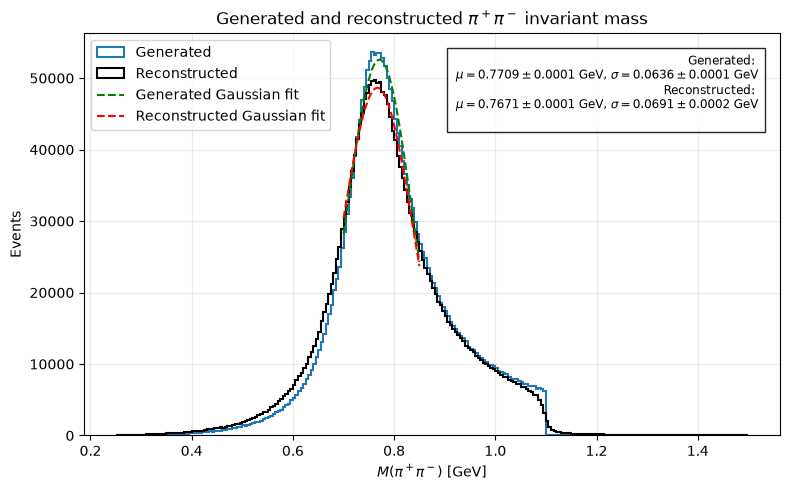

In [10]:
bins = np.linspace(0.25, 1.50, 251)
GAUSSIAN_FIT_RANGE = (0.7, 0.85)

def gaussian(x, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

def fit_gaussian_to_histogram(values, bins, fit_range):
    counts, edges = np.histogram(values, bins=bins)
    centers = 0.5 * (edges[:-1] + edges[1:])
    fit_mask = (centers >= fit_range[0]) & (centers <= fit_range[1]) & (counts > 0)
    x_fit = centers[fit_mask]
    y_fit = counts[fit_mask]
    initial_mean = x_fit[np.argmax(y_fit)]
    parameters, covariance = curve_fit(
        gaussian, x_fit, y_fit,
        p0=(y_fit.max(), initial_mean, 0.07),
        sigma=np.sqrt(y_fit), absolute_sigma=True,
        bounds=([0.0, fit_range[0], 0.001], [np.inf, fit_range[1], 0.30]),
        maxfev=20_000,
    )
    errors = np.sqrt(np.diag(covariance))
    return parameters, errors

gen_fit, gen_fit_error = fit_gaussian_to_histogram(
    m_pipi_gen, bins, GAUSSIAN_FIT_RANGE
)
rec_fit, rec_fit_error = fit_gaussian_to_histogram(
    m_pipi, bins, GAUSSIAN_FIT_RANGE
)
gen_amplitude, gen_mean, gen_sigma = gen_fit
rec_amplitude, rec_mean, rec_sigma = rec_fit
fit_x = np.linspace(*GAUSSIAN_FIT_RANGE, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(m_pipi_gen, bins=bins, histtype="step", linewidth=1.5,
        color="tab:blue", label="Generated")
ax.hist(m_pipi, bins=bins, histtype="step", linewidth=1.5,
        color="black", label="Reconstructed")
ax.plot(fit_x, gaussian(fit_x, *gen_fit), color="green", linestyle="--",
        linewidth=1.5, label="Generated Gaussian fit")
ax.plot(fit_x, gaussian(fit_x, *rec_fit), color="red", linestyle="--",
        linewidth=1.5, label="Reconstructed Gaussian fit")
ax.set(
    xlabel=r"$M(\pi^+\pi^-)$ [GeV]",
    ylabel="Events",
    title=r"Generated and reconstructed $\pi^+\pi^-$ invariant mass",
)
fit_text = (
  
    f"Generated: \n $\mu={gen_mean:.4f}\pm{gen_fit_error[1]:.4f}$ GeV, "
    f"$\sigma={gen_sigma:.4f}\pm{gen_fit_error[2]:.4f}$ GeV\n"

    f"Reconstructed: \n $\mu={rec_mean:.4f}\pm{rec_fit_error[1]:.4f}$ GeV, "
    f"$\sigma={rec_sigma:.4f}\pm{rec_fit_error[2]:.4f}$ GeV\n"
)
ax.text(0.97, 0.95, fit_text,
        transform=ax.transAxes,
        ha="right", va="top", fontsize=8.5,
        bbox=dict(facecolor="white", alpha=0.85))
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Reconstructed electron events: 4,844,809


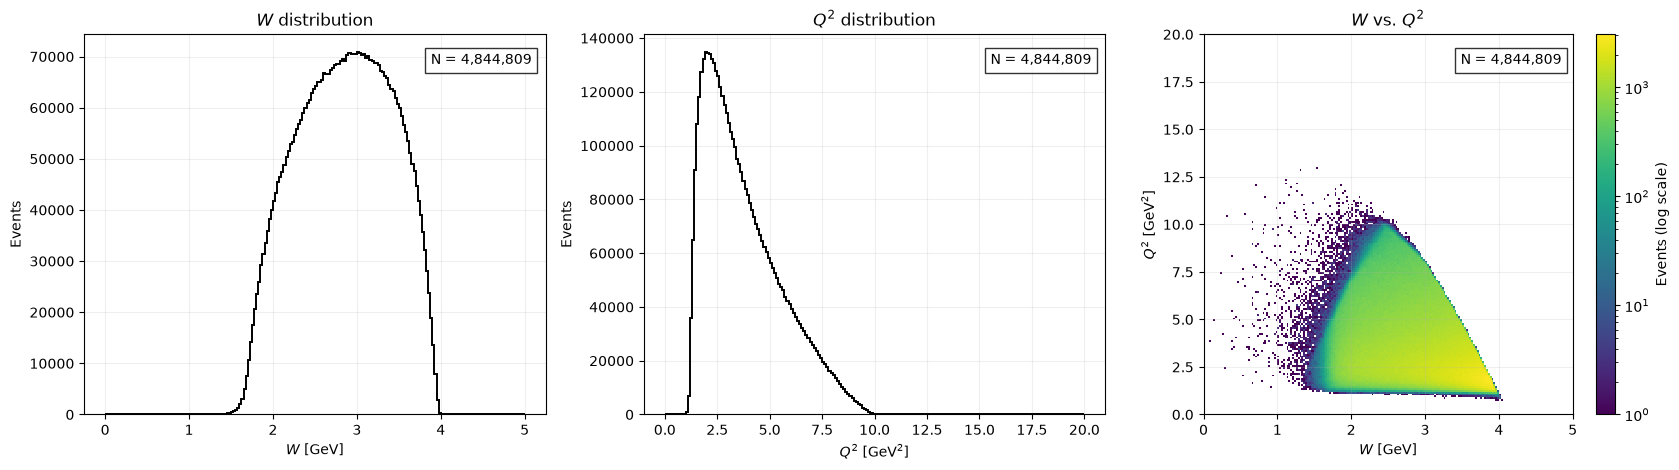

In [18]:
# Inclusive kinematics from the reconstructed scattered electron,
# using the massless-electron approximation.
BEAM_ENERGY_GEV = 10.6
PROTON_MASS_GEV = 0.9382720813

electron_columns = ["pid_gen", "px_rec", "py_rec", "pz_rec"]
electron_selection = (
    "(reconstructed == 1)"
    " & (pid_gen == 11)"
    " & (pid_rec == 11)"
    " & (triggered == 1)"
    " & (is_trigger_particle == 1)"
    " & (trigger_pid_rec == 11)"
    "& (detector == 1)"
    "& (p_rec >= 2)"

)
w_chunks, q2_chunks = [], []

for electrons in tree.iterate(
    expressions=electron_columns,
    cut=electron_selection,
    step_size="128 MB",
    library="np",
):
    px = electrons["px_rec"]
    py = electrons["py_rec"]
    pz = electrons["pz_rec"]
    electron_energy = np.sqrt(px**2 + py**2 + pz**2)

    q2_chunk = 2 * BEAM_ENERGY_GEV * (electron_energy - pz)
    w2_chunk = (
        PROTON_MASS_GEV**2
        + 2 * PROTON_MASS_GEV * (BEAM_ENERGY_GEV - electron_energy)
        - q2_chunk
    )
    valid = np.isfinite(q2_chunk) & np.isfinite(w2_chunk) & (q2_chunk > 0) & (w2_chunk > 0)
    q2_chunks.append(q2_chunk[valid].astype(np.float32))
    w_chunks.append(np.sqrt(w2_chunk[valid]).astype(np.float32))

q2 = np.concatenate(q2_chunks)
w = np.concatenate(w_chunks)
print(f"Reconstructed electron events: {len(w):,}")

w_bins = np.linspace(0.0, 5.0, 201)
q2_bins = np.linspace(0.0, 20.0, 201)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].hist(w, bins=w_bins, histtype="step", linewidth=1.4, color="black")
axes[0].set(xlabel=r"$W$ [GeV]", ylabel="Events", title=r"$W$ distribution")
axes[0].text(0.97, 0.95, f"N = {len(w):,}", transform=axes[0].transAxes,
             ha="right", va="top", bbox=dict(facecolor="white", alpha=0.8))

axes[1].hist(q2, bins=q2_bins, histtype="step", linewidth=1.4, color="black")
#axes[1].set_yscale("log")
axes[1].set(xlabel=r"$Q^2$ [GeV$^2$]", ylabel="Events", title=r"$Q^2$ distribution")
axes[1].text(0.97, 0.95, f"N = {len(q2):,}", transform=axes[1].transAxes,
             ha="right", va="top", bbox=dict(facecolor="white", alpha=0.8))

density = axes[2].hist2d(w, q2, bins=[w_bins, q2_bins], norm=LogNorm(), cmap="viridis")
axes[2].set(xlabel=r"$W$ [GeV]", ylabel=r"$Q^2$ [GeV$^2$]", title=r"$W$ vs. $Q^2$")
axes[2].text(0.97, 0.95, f"N = {len(w):,}", transform=axes[2].transAxes,
             ha="right", va="top", bbox=dict(facecolor="white", alpha=0.8))
fig.colorbar(density[3], ax=axes[2], label="Events (log scale)")

for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


Exclusive e pi+ pi- candidates: 800,916


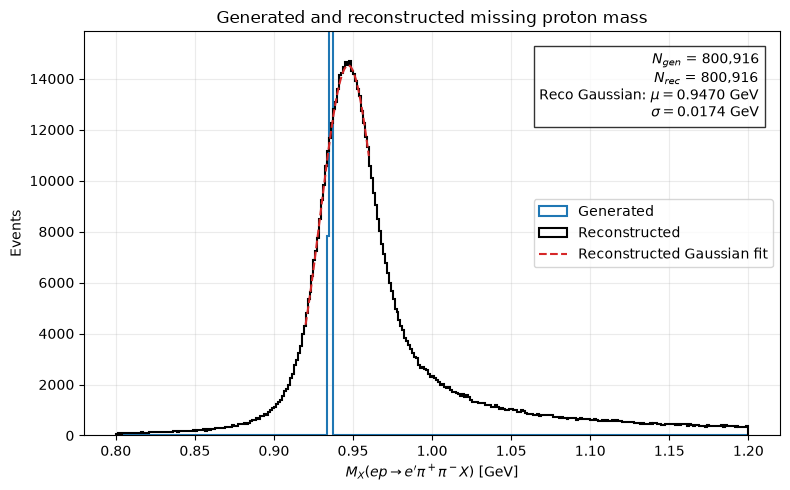

In [12]:
# Missing mass for ep -> e' pi+ pi- X; exclusive events peak at M_p.
missing_columns = [
    "file_id", "event", "pid_gen",
    "px_rec", "py_rec", "pz_rec",
    "px_gen", "py_gen", "pz_gen",
]
missing_selection = (
    "(reconstructed == 1) & ("
    "((pid_gen == 11) & (pid_rec == 11) & (triggered == 1)"
    " & (is_trigger_particle == 1) & (trigger_pid_rec == 11)) | "
    "((pid_gen == 211) & (pid_rec == 211)) | "
    "((pid_gen == -211) & (pid_rec == -211))"
    " & (detector == 1)"
    ")"
)
event_key = ["file_id", "event"]
missing_mass2_rec_chunks, missing_mass2_gen_chunks = [], []
missing_carry = None
momentum_columns = [f"p{axis}_{kind}" for kind in ("rec", "gen") for axis in "xyz"]

def missing_proton_mass_squared(rows):
    def particle(pid, label):
        selected = rows.loc[rows["pid_gen"] == pid, event_key + momentum_columns].copy()
        return selected.rename(columns={name: f"{name}_{label}" for name in momentum_columns})

    electron = particle(11, "electron")
    pi_plus = particle(211, "plus")
    pi_minus = particle(-211, "minus")
    events = electron.merge(pi_plus, on=event_key, validate="one_to_one").merge(
        pi_minus, on=event_key, validate="one_to_one"
    )

    def calculate(kinematics):
        p2_electron = sum(events[f"p{axis}_{kinematics}_electron"] ** 2 for axis in "xyz")
        p2_plus = sum(events[f"p{axis}_{kinematics}_plus"] ** 2 for axis in "xyz")
        p2_minus = sum(events[f"p{axis}_{kinematics}_minus"] ** 2 for axis in "xyz")
        missing_energy = (
            BEAM_ENERGY_GEV + PROTON_MASS_GEV
            - np.sqrt(p2_electron)
            - np.sqrt(p2_plus + PION_MASS_GEV**2)
            - np.sqrt(p2_minus + PION_MASS_GEV**2)
        )
        missing_px = -(
            events[f"px_{kinematics}_electron"]
            + events[f"px_{kinematics}_plus"]
            + events[f"px_{kinematics}_minus"]
        )
        missing_py = -(
            events[f"py_{kinematics}_electron"]
            + events[f"py_{kinematics}_plus"]
            + events[f"py_{kinematics}_minus"]
        )
        missing_pz = BEAM_ENERGY_GEV - (
            events[f"pz_{kinematics}_electron"]
            + events[f"pz_{kinematics}_plus"]
            + events[f"pz_{kinematics}_minus"]
        )
        return (missing_energy**2 - missing_px**2 - missing_py**2 - missing_pz**2).to_numpy(
            dtype=np.float32
        )

    return calculate("rec"), calculate("gen")

for chunk in tree.iterate(
    expressions=missing_columns,
    cut=missing_selection,
    step_size="128 MB",
    library="pd",
):
    rows = chunk if missing_carry is None else pd.concat([missing_carry, chunk], ignore_index=True)
    if rows.empty:
        continue

    last_file_id = rows.iloc[-1]["file_id"]
    last_event = rows.iloc[-1]["event"]
    is_last_event = (rows["file_id"] == last_file_id) & (rows["event"] == last_event)
    missing_mass2_rec, missing_mass2_gen = missing_proton_mass_squared(rows.loc[~is_last_event])
    missing_mass2_rec_chunks.append(missing_mass2_rec)
    missing_mass2_gen_chunks.append(missing_mass2_gen)
    missing_carry = rows.loc[is_last_event].copy()

missing_mass2_rec, missing_mass2_gen = missing_proton_mass_squared(missing_carry)
missing_mass2_rec_chunks.append(missing_mass2_rec)
missing_mass2_gen_chunks.append(missing_mass2_gen)
missing_mass2_proton = np.concatenate(missing_mass2_rec_chunks)
missing_mass2_proton_gen = np.concatenate(missing_mass2_gen_chunks)
common_mass_mask = (
    np.isfinite(missing_mass2_proton)
    & np.isfinite(missing_mass2_proton_gen)
    & (missing_mass2_proton >= 0)
    & (missing_mass2_proton_gen >= 0)
)
missing_mass2_proton = missing_mass2_proton[common_mass_mask]
missing_mass2_proton_gen = missing_mass2_proton_gen[common_mass_mask]
missing_mass_proton = np.sqrt(missing_mass2_proton)
missing_mass_proton_gen = np.sqrt(missing_mass2_proton_gen)
assert len(missing_mass_proton) == len(missing_mass_proton_gen)
print(f"Exclusive e pi+ pi- candidates: {len(missing_mass_proton):,}")

fig, ax = plt.subplots(figsize=(8, 5))
missing_mass_bins = np.linspace(0.8, 1.2, 321)
ax.hist(missing_mass_proton_gen, bins=missing_mass_bins, histtype="step",
        linewidth=1.5, color="tab:blue", label="Generated")
rec_counts, _, _ = ax.hist(
        missing_mass_proton, bins=missing_mass_bins, histtype="step",
        linewidth=1.5, color="black", label="Reconstructed")

MISSING_MASS_FIT_RANGE = (0.92, 0.96)
missing_mass_centers = 0.5 * (missing_mass_bins[:-1] + missing_mass_bins[1:])
missing_fit_mask = (
    (missing_mass_centers >= MISSING_MASS_FIT_RANGE[0])
    & (missing_mass_centers <= MISSING_MASS_FIT_RANGE[1])
    & (rec_counts > 0)
)
missing_fit_x = missing_mass_centers[missing_fit_mask]
missing_fit_y = rec_counts[missing_fit_mask]
missing_fit_parameters, _ = curve_fit(
    gaussian, missing_fit_x, missing_fit_y,
    p0=(missing_fit_y.max(), missing_fit_x[np.argmax(missing_fit_y)], 0.03),
    sigma=np.sqrt(missing_fit_y), absolute_sigma=True,
    bounds=(
        [0.0, MISSING_MASS_FIT_RANGE[0], 0.001],
        [np.inf, MISSING_MASS_FIT_RANGE[1], 0.25],
    ),
    maxfev=20_000,
)
missing_fit_amplitude, missing_fit_mean, missing_fit_sigma = missing_fit_parameters
missing_fit_curve_x = np.linspace(*MISSING_MASS_FIT_RANGE, 500)
ax.plot(
    missing_fit_curve_x, gaussian(missing_fit_curve_x, *missing_fit_parameters),
    color="tab:red", linestyle="--", linewidth=1.5,
    label="Reconstructed Gaussian fit",
)
# ax.axvline(PROTON_MASS_GEV, color="tab:red", linestyle="--", label=rf"$M_p = {PROTON_MASS_GEV:.3f}$ GeV")
ax.set(
    xlabel=r"$M_X(e p \rightarrow e' \pi^+ \pi^- X)$ [GeV]",
    ylabel="Events",
    title="Generated and reconstructed missing proton mass",
)
ax.set_ylim(0, 1.08 * rec_counts.max())
ax.text(0.97, 0.95,
        f"$N_{{gen}}$ = {len(missing_mass_proton_gen):,}\n"
        f"$N_{{rec}}$ = {len(missing_mass_proton):,}\n"
        f"Reco Gaussian: $\mu={missing_fit_mean:.4f}$ GeV\n"
        f"$\sigma={missing_fit_sigma:.4f}$ GeV",
        transform=ax.transAxes,
        ha="right", va="top", bbox=dict(facecolor="white", alpha=0.8))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


In [13]:
# Generated versus energy-loss-corrected reconstructed kinematics.
# Every particle used below is required to have was_corrected == 1.
import duckdb

CORRECTED_PARQUET_PATH = Path(
    "parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet"
)
if not CORRECTED_PARQUET_PATH.is_file():
    raise FileNotFoundError(CORRECTED_PARQUET_PATH)
corrected_parquet_sql = CORRECTED_PARQUET_PATH.as_posix().replace("'", "''")

corrected_pion_pairs = duckdb.sql(
    f"""
    SELECT
        pp.px_gen AS px_gen_plus, pp.py_gen AS py_gen_plus, pp.pz_gen AS pz_gen_plus,
        pp.px_rec AS px_rec_plus, pp.py_rec AS py_rec_plus, pp.pz_rec AS pz_rec_plus,
        pm.px_gen AS px_gen_minus, pm.py_gen AS py_gen_minus, pm.pz_gen AS pz_gen_minus,
        pm.px_rec AS px_rec_minus, pm.py_rec AS py_rec_minus, pm.pz_rec AS pz_rec_minus
    FROM read_parquet('{corrected_parquet_sql}') AS pp
    INNER JOIN read_parquet('{corrected_parquet_sql}') AS pm
        ON pp.file_id = pm.file_id AND pp.event = pm.event
    WHERE pp.was_corrected = 1
      AND pm.was_corrected = 1
      AND pp.reconstructed = 1 AND pm.reconstructed = 1
      AND pp.pid_gen = 211 AND pp.pid_rec = 211
      AND pm.pid_gen = -211 AND pm.pid_rec = -211
    """
).fetchnumpy()

def corrected_pair_mass(arrays, kinematics):
    p2_plus = sum(arrays[f"p{axis}_{kinematics}_plus"] ** 2 for axis in "xyz")
    p2_minus = sum(arrays[f"p{axis}_{kinematics}_minus"] ** 2 for axis in "xyz")
    energy = np.sqrt(p2_plus + PION_MASS_GEV**2) + np.sqrt(
        p2_minus + PION_MASS_GEV**2
    )
    total_p2 = sum(
        (arrays[f"p{axis}_{kinematics}_plus"] + arrays[f"p{axis}_{kinematics}_minus"]) ** 2
        for axis in "xyz"
    )
    return np.sqrt(np.clip(energy**2 - total_p2, 0, None))

corrected_m_pipi_gen = corrected_pair_mass(corrected_pion_pairs, "gen")
corrected_m_pipi_rec = corrected_pair_mass(corrected_pion_pairs, "rec")
corrected_mass_mask = np.isfinite(corrected_m_pipi_gen) & np.isfinite(corrected_m_pipi_rec)
corrected_m_pipi_gen = corrected_m_pipi_gen[corrected_mass_mask]
corrected_m_pipi_rec = corrected_m_pipi_rec[corrected_mass_mask]
assert len(corrected_m_pipi_gen) == len(corrected_m_pipi_rec)

corrected_complete_events = duckdb.sql(
    f"""
    SELECT
        e.px_gen AS px_gen_electron, e.py_gen AS py_gen_electron, e.pz_gen AS pz_gen_electron,
        e.px_rec AS px_rec_electron, e.py_rec AS py_rec_electron, e.pz_rec AS pz_rec_electron,
        pp.px_gen AS px_gen_plus, pp.py_gen AS py_gen_plus, pp.pz_gen AS pz_gen_plus,
        pp.px_rec AS px_rec_plus, pp.py_rec AS py_rec_plus, pp.pz_rec AS pz_rec_plus,
        pm.px_gen AS px_gen_minus, pm.py_gen AS py_gen_minus, pm.pz_gen AS pz_gen_minus,
        pm.px_rec AS px_rec_minus, pm.py_rec AS py_rec_minus, pm.pz_rec AS pz_rec_minus
    FROM read_parquet('{corrected_parquet_sql}') AS e
    INNER JOIN read_parquet('{corrected_parquet_sql}') AS pp
        ON e.file_id = pp.file_id AND e.event = pp.event
    INNER JOIN read_parquet('{corrected_parquet_sql}') AS pm
        ON e.file_id = pm.file_id AND e.event = pm.event
    WHERE e.was_corrected = 1
      AND pp.was_corrected = 1
      AND pm.was_corrected = 1
      AND e.reconstructed = 1 AND pp.reconstructed = 1 AND pm.reconstructed = 1
      AND e.pid_gen = 11 AND e.pid_rec = 11
      AND e.triggered = 1 AND e.is_trigger_particle = 1 AND e.trigger_pid_rec = 11
      AND pp.pid_gen = 211 AND pp.pid_rec = 211
      AND pm.pid_gen = -211 AND pm.pid_rec = -211
    """
).fetchnumpy()

def corrected_missing_mass2(arrays, kinematics):
    p2_electron = sum(arrays[f"p{axis}_{kinematics}_electron"] ** 2 for axis in "xyz")
    p2_plus = sum(arrays[f"p{axis}_{kinematics}_plus"] ** 2 for axis in "xyz")
    p2_minus = sum(arrays[f"p{axis}_{kinematics}_minus"] ** 2 for axis in "xyz")
    missing_energy = (
        BEAM_ENERGY_GEV + PROTON_MASS_GEV
        - np.sqrt(p2_electron)
        - np.sqrt(p2_plus + PION_MASS_GEV**2)
        - np.sqrt(p2_minus + PION_MASS_GEV**2)
    )
    missing_px = -(
        arrays[f"px_{kinematics}_electron"]
        + arrays[f"px_{kinematics}_plus"]
        + arrays[f"px_{kinematics}_minus"]
    )
    missing_py = -(
        arrays[f"py_{kinematics}_electron"]
        + arrays[f"py_{kinematics}_plus"]
        + arrays[f"py_{kinematics}_minus"]
    )
    missing_pz = BEAM_ENERGY_GEV - (
        arrays[f"pz_{kinematics}_electron"]
        + arrays[f"pz_{kinematics}_plus"]
        + arrays[f"pz_{kinematics}_minus"]
    )
    return missing_energy**2 - missing_px**2 - missing_py**2 - missing_pz**2

corrected_missing_mass2_gen = corrected_missing_mass2(corrected_complete_events, "gen")
corrected_missing_mass2_rec = corrected_missing_mass2(corrected_complete_events, "rec")
corrected_missing_mask = (
    np.isfinite(corrected_missing_mass2_gen)
    & np.isfinite(corrected_missing_mass2_rec)
    & (corrected_missing_mass2_gen >= 0)
    & (corrected_missing_mass2_rec >= 0)
)
corrected_missing_mass_gen = np.sqrt(corrected_missing_mass2_gen[corrected_missing_mask])
corrected_missing_mass_rec = np.sqrt(corrected_missing_mass2_rec[corrected_missing_mask])
assert len(corrected_missing_mass_gen) == len(corrected_missing_mass_rec)

def corrected_gaussian_fit(values, bins, fit_range):
    counts, edges = np.histogram(values, bins=bins)
    centers = 0.5 * (edges[:-1] + edges[1:])
    mask = (centers >= fit_range[0]) & (centers <= fit_range[1]) & (counts > 0)
    x_fit, y_fit = centers[mask], counts[mask]
    parameters, covariance = curve_fit(
        gaussian, x_fit, y_fit,
        p0=(y_fit.max(), x_fit[np.argmax(y_fit)], 0.06),
        sigma=np.sqrt(y_fit), absolute_sigma=True,
        bounds=([0.0, fit_range[0], 0.001], [np.inf, fit_range[1], 0.30]),
        maxfev=20_000,
    )
    return parameters, np.sqrt(np.diag(covariance))

corrected_mass_bins = np.linspace(0.25, 1.50, 251)
CORRECTED_MASS_FIT_RANGE = (0.65, 0.90)
corrected_gen_fit, corrected_gen_fit_error = corrected_gaussian_fit(
    corrected_m_pipi_gen, corrected_mass_bins, CORRECTED_MASS_FIT_RANGE
)
corrected_rec_fit, corrected_rec_fit_error = corrected_gaussian_fit(
    corrected_m_pipi_rec, corrected_mass_bins, CORRECTED_MASS_FIT_RANGE
)
corrected_fit_x = np.linspace(*CORRECTED_MASS_FIT_RANGE, 500)

corrected_missing_bins = np.linspace(0.5, 1.5, 321)
CORRECTED_MISSING_FIT_RANGE = (0.92, 0.98)
corrected_missing_rec_fit, _ = corrected_gaussian_fit(
    corrected_missing_mass_rec, corrected_missing_bins, CORRECTED_MISSING_FIT_RANGE
)
corrected_missing_fit_x = np.linspace(*CORRECTED_MISSING_FIT_RANGE, 500)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(corrected_m_pipi_gen, bins=corrected_mass_bins, histtype="step",
             linewidth=1.5, color="tab:blue", label="Generated")
axes[0].hist(corrected_m_pipi_rec, bins=corrected_mass_bins, histtype="step",
             linewidth=1.5, color="black", label="Corrected reconstructed")
axes[0].plot(corrected_fit_x, gaussian(corrected_fit_x, *corrected_gen_fit),
             color="tab:blue", linestyle="--", linewidth=1.5,
             label="Generated Gaussian fit")
axes[0].plot(corrected_fit_x, gaussian(corrected_fit_x, *corrected_rec_fit),
             color="tab:red", linestyle="--", linewidth=1.5,
             label="Corrected Gaussian fit")
axes[0].set(
    xlabel=r"$M(\pi^+\pi^-)$ [GeV]", ylabel="Events",
    title=r"Corrected particles: $\pi^+\pi^-$ invariant mass",
)
axes[0].text(
    0.97, 0.95,
    f"$N_{{gen}}=N_{{corr}}$ = {len(corrected_m_pipi_gen):,}\n"
    f"Generated: $\mu={corrected_gen_fit[1]:.4f}$, "
    f"$\sigma={corrected_gen_fit[2]:.4f}$ GeV\n"
    f"Corrected: $\mu={corrected_rec_fit[1]:.4f}$, "
    f"$\sigma={corrected_rec_fit[2]:.4f}$ GeV",
    transform=axes[0].transAxes, ha="right", va="top", fontsize=8.5,
    bbox=dict(facecolor="white", alpha=0.85),
)
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.25)

axes[1].hist(corrected_missing_mass_gen, bins=corrected_missing_bins,
             histtype="step", linewidth=1.5, color="tab:blue",
             label="Generated")
corrected_missing_counts, _, _ = axes[1].hist(
    corrected_missing_mass_rec, bins=corrected_missing_bins, histtype="step",
    linewidth=1.5, color="black", label="Corrected reconstructed",
)
axes[1].plot(
    corrected_missing_fit_x, gaussian(corrected_missing_fit_x, *corrected_missing_rec_fit),
    color="tab:red", linestyle="--", linewidth=1.5,
    label="Corrected Gaussian fit",
)
axes[1].set(
    xlabel=r"$M_X(e p \rightarrow e' \pi^+ \pi^- X)$ [GeV]",
    ylabel="Events", title="Corrected particles: missing proton mass",
)
axes[1].set_ylim(0, 1.08 * corrected_missing_counts.max())
axes[1].text(
    0.97, 0.95,
    f"$N_{{gen}}=N_{{corr}}$ = {len(corrected_missing_mass_gen):,}\n"
    f"Corrected Gaussian: $\mu={corrected_missing_rec_fit[1]:.4f}$ GeV\n"
    f"$\sigma={corrected_missing_rec_fit[2]:.4f}$ GeV",
    transform=axes[1].transAxes, ha="right", va="top", fontsize=8.5,
    bbox=dict(facecolor="white", alpha=0.85),
)
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()
print(f"Corrected pion-pair events: {len(corrected_m_pipi_gen):,}")
print(f"Corrected complete e pi+ pi- events: {len(corrected_missing_mass_gen):,}")


FileNotFoundError: parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet